# Step 2 — Friend communities (Louvain, implemented from scratch)

**Project question:** *Are friend communities also taste communities?*
(DTU 02807 Computational Tools for Data Science, Yelp Open Dataset)

This notebook covers **point 2 of the pipeline**: detect communities in the Philadelphia friendship graph with **Louvain** and evaluate them with **modularity**. The output is one community label per user, which the later steps compare with the taste communities (NMI / ARI, permutation test).

| Section | What it does |
|---|---|
| 2a | Load the cleaned friendship graph from step 1. |
| 2b | **Louvain written from scratch** (local moving + aggregation), and a check of the modularity formula. |
| 2c | Validate our implementation: Zachary's karate club, and our Louvain vs `networkx` on the real graph. |
| 2d | Run it with 20 random seeds: modularity, number of communities, **stability** between runs. |
| 2e | Effect of the **resolution parameter**, to justify the value we use. |
| 2f | Analyse the final communities: sizes, density, hubs, user profile. |
| 2g | **Robustness**: remove the hubs, and compare with a degree-preserving random graph. |
| 2h | Save the partition to `data/processed/` for steps 3–5. |

**Input:** `data/processed/philadelphia_pa_friend_edges.parquet` and `philadelphia_pa_users.parquet` (produced by `01_data_cleaning.ipynb`).
**Output:** `philadelphia_pa_friend_communities.parquet` (`user_id`, `friend_community`) and a JSON summary.

**Run:** `jupyter lab notebooks/02_friend_communities.ipynb`, then *Run → Run All Cells*. It needs `pandas numpy networkx matplotlib pyarrow scikit-learn` and takes a few minutes (the Louvain runs are pure Python).

## 0. Setup

Imports, paths, the random seed and the parameters of the analysis. Everything that can be tuned is in this cell.

In [1]:
import json
import platform
import random
import time
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker
import networkx as nx
import numpy as np
import pandas as pd
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# ---------------- Paths (relative to the project root) ----------------
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
FIGURES = PROJECT_ROOT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
P = str(DATA_PROCESSED / "philadelphia_pa_")  # prefix of the files written by step 1

# ---------------- Parameters ----------------
N_SEEDS = 20                       # independent Louvain runs on the real graph
RESOLUTION = 1.0                   # gamma = 1 is the standard modularity used in the course
RESOLUTIONS = [0.5, 0.75, 1.0, 1.25, 1.5, 2.0]   # values compared in section 2e
SEEDS_PER_RESOLUTION = 5
HUB_QUANTILE = 0.99                # "hub" = top 1% of users by number of friends
N_NULL_GRAPHS = 3                  # degree-preserving random graphs in section 2g
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# ---------------- Plot style (same as step 1) ----------------
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | networkx {nx.__version__}")
print(f"PROJECT_ROOT = {PROJECT_ROOT}")

Python 3.12.9 | pandas 3.0.1 | numpy 2.4.3 | networkx 3.7
PROJECT_ROOT = C:\Users\matti\m\DTU\Corsi\Computational Tools for Data Science\progetto\repo\Computational-tools-4-datasciense


## 2a. Load the friendship graph

We load the edge list and the user table written by step 1 and build an **undirected, unweighted** graph (step 1 showed that 100% of friend links are reciprocated). The nodes are sorted so the graph, and therefore the seeded runs, are reproducible.

In [2]:
edges = pd.read_parquet(P + "friend_edges.parquet")
users = pd.read_parquet(P + "users.parquet").set_index("user_id")

G = nx.Graph()
G.add_nodes_from(sorted(users.index))
G.add_edges_from(sorted(zip(edges.u, edges.v)))

print(f"Nodes: {G.number_of_nodes():,}   Edges: {G.number_of_edges():,}")
print(f"Connected: {nx.is_connected(G)}   Self-loops: {nx.number_of_selfloops(G)}")
print(f"Mean degree: {2 * G.number_of_edges() / G.number_of_nodes():.1f}   density: {nx.density(G):.2e}")
assert set(G.nodes) == set(users.index) and nx.is_connected(G)
assert dict(G.degree()) == users.degree.to_dict(), "degrees must match the users table of step 1"

Nodes: 7,947   Edges: 67,622
Connected: True   Self-loops: 0
Mean degree: 17.0   density: 2.14e-03


## 2b. Louvain from scratch

**Modularity** measures how much more densely the communities are connected inside than expected in a random graph with the same degrees:

$$Q=\sum_{C}\left[\frac{\Sigma_{in}(C)}{2m}-\gamma\left(\frac{\Sigma_{tot}(C)}{2m}\right)^2\right]$$

where $m$ is the number of edges, $\Sigma_{in}(C)$ is the sum of the degrees' internal part (every internal edge counted twice), $\Sigma_{tot}(C)$ is the sum of the degrees of the nodes in $C$, and $\gamma$ is the **resolution** ($\gamma=1$ is the standard definition from the course).

**Louvain** repeats two phases until modularity stops improving:
1. **Local moving.** Visit the nodes in random order. Remove node $i$ from its community and put it in the neighbouring community (or back in its own) that gives the largest gain
$$\Delta Q \propto k_{i,C}-\gamma\,\frac{\Sigma_{tot}(C)\,k_i}{2m},$$
where $k_{i,C}$ is the weight of the links from $i$ to $C$ and $k_i$ is the degree of $i$. Repeat until no node moves.
2. **Aggregation.** Collapse every community into one super-node. Links between communities are summed, and the links inside a community become a self-loop. Go back to phase 1 on the smaller graph.

The result is a hierarchy of partitions. We keep the last (coarsest) level. The algorithm is greedy and the visiting order is random, so different seeds can give different partitions. Section 2d measures how much.

Implementation notes: the graph is stored as a list of dictionaries (`adj[i][j] = weight`). A self-loop `adj[c][c]` holds the weight of all links inside the community with each internal edge counted twice. This way the degree of a super-node is just the sum of its dictionary and $2m$ never changes. The code uses only the standard library.

**Connectivity fix.** Louvain has a known defect (Traag, Waltman & van Eck, 2019): when a node that bridges two parts of a community moves away, the community can be left **internally disconnected**, and later aggregation steps can never split it again. We therefore add a post-processing step, `split_disconnected`, which replaces every disconnected community by its connected components. This can only **raise** $Q$: the internal edges stay the same, while $\sum_C \Sigma_{tot}(C)^2$ gets smaller. `louvain_connected` = Louvain + this step, and it is what we use from section 2d on (section 2c validates plain Louvain).

In [3]:
def modularity(G, labels, gamma=1.0):
    # Modularity of a partition {node: community}, straight from the definition (independent of Louvain).
    m2 = 2 * G.number_of_edges()
    inside, total = Counter(), Counter()
    for u, v in G.edges():
        if labels[u] == labels[v]:
            inside[labels[u]] += 2
    for u, d in G.degree():
        total[labels[u]] += d
    return sum(inside[c] / m2 - gamma * (total[c] / m2) ** 2 for c in total)


def to_adjacency(G, index):
    adj = [dict() for _ in range(len(index))]
    for u, v in G.edges():
        if u != v:
            adj[index[u]][index[v]] = 1.0
            adj[index[v]][index[u]] = 1.0
    return adj


def local_moving(adj, gamma, rng):
    # Phase 1: move single nodes to the neighbouring community with the best gain until no node moves.
    n = len(adj)
    k = [sum(a.values()) for a in adj]          # degree of each (super-)node, self-loop included
    m2 = sum(k)                                  # 2m
    comm = list(range(n))                        # every node starts alone
    tot = k[:]                                   # sum of degrees of each community
    order = list(range(n))
    moved_any, improved = False, True
    while improved:
        improved = False
        rng.shuffle(order)
        for i in order:
            ci = comm[i]
            w = defaultdict(float)               # weight from i to each neighbouring community
            for j, wij in adj[i].items():
                if j != i:
                    w[comm[j]] += wij
            tot[ci] -= k[i]                      # take i out of its community
            best, best_gain = ci, w.get(ci, 0.0) - gamma * tot[ci] * k[i] / m2
            for c, wc in w.items():
                gain = wc - gamma * tot[c] * k[i] / m2
                if gain > best_gain + 1e-12:     # strict improvement, so ties keep the node where it is
                    best, best_gain = c, gain
            tot[best] += k[i]
            if best != ci:
                comm[i] = best
                improved = moved_any = True
    return comm, moved_any


def aggregate(adj, comm):
    # Phase 2: one super-node per community; parallel links are summed, internal links become a self-loop.
    ids = {c: x for x, c in enumerate(sorted(set(comm)))}
    c2 = [ids[c] for c in comm]
    new = [defaultdict(float) for _ in ids]
    for i, a in enumerate(adj):
        for j, w in a.items():
            new[c2[i]][c2[j]] += w
    return [dict(d) for d in new], c2


def louvain(G, gamma=1.0, seed=0):
    # Returns (partition {node: community}, list of partitions after each aggregation level).
    rng = random.Random(seed)
    nodes = list(G.nodes())
    index = {u: i for i, u in enumerate(nodes)}
    adj = to_adjacency(G, index)
    membership = list(range(len(nodes)))         # original node -> current super-node
    levels = []
    while True:
        comm, moved = local_moving(adj, gamma, rng)
        if not moved:
            break
        adj, c2 = aggregate(adj, comm)
        membership = [c2[m] for m in membership]
        levels.append({u: membership[index[u]] for u in nodes})
    if not levels:                               # nothing moved: every node is its own community
        levels.append({u: index[u] for u in nodes})
    return levels[-1], levels


def n_communities(part):
    return len(set(part.values()))


def split_disconnected(G, part):
    # Replace every internally disconnected community by its connected components.
    # Returns (new partition, number of communities that had to be split). Never lowers Q.
    groups = defaultdict(list)
    for u, c in part.items():
        groups[c].append(u)
    new, n_split, next_id = {}, 0, 0
    for c in sorted(groups):
        comps = list(nx.connected_components(G.subgraph(groups[c])))
        n_split += len(comps) > 1
        for comp in sorted(comps, key=lambda s: (-len(s), min(s))):   # deterministic order
            for u in comp:
                new[u] = next_id
            next_id += 1
    return new, n_split


def louvain_connected(G, gamma=1.0, seed=0):
    part, _ = louvain(G, gamma=gamma, seed=seed)
    return split_disconnected(G, part)[0]

## 2c. Validating our implementation

We cannot trust our own code just because it runs, so we check it in three ways:
1. **Modularity formula:** our `modularity()` must agree with `networkx` on the same partition.
2. **Zachary's karate club:** a 34-node graph where the best known Louvain modularity is about 0.419.
3. **The real graph:** the modularity of our Louvain must be in the same range as the one from `networkx.community.louvain_communities`.

In [4]:
# 1+2. karate club
K = nx.Graph(nx.karate_club_graph().edges())   # drop the edge weights that newer networkx versions attach
q_ours = [modularity(K, louvain(K, seed=s)[0]) for s in range(30)]
p_ref = nx.community.louvain_communities(K, seed=0)
ref_labels = {u: i for i, c in enumerate(p_ref) for u in c}
assert abs(modularity(K, ref_labels) - nx.community.modularity(K, p_ref)) < 1e-12, "modularity() disagrees with networkx"
print(f"Karate club: our Louvain Q over 30 seeds = {np.mean(q_ours):.4f} (max {np.max(q_ours):.4f}); best known ~ 0.4198")
print("modularity() agrees with networkx on the reference partition: OK")

# 3. real graph, a quick comparison on 5 seeds
t0 = time.perf_counter()
ours = [modularity(G, louvain(G, seed=s)[0]) for s in range(5)]
t_ours = (time.perf_counter() - t0) / 5
t0 = time.perf_counter()
ref = [nx.community.modularity(G, nx.community.louvain_communities(G, seed=s)) for s in range(5)]
t_ref = (time.perf_counter() - t0) / 5
print(f"\nPhiladelphia graph, 5 seeds each:")
print(f"  ours     : Q = {np.mean(ours):.4f} +- {np.std(ours):.4f}   ({t_ours:.1f} s per run)")
print(f"  networkx : Q = {np.mean(ref):.4f} +- {np.std(ref):.4f}   ({t_ref:.1f} s per run)")

Karate club: our Louvain Q over 30 seeds = 0.4165 (max 0.4198); best known ~ 0.4198
modularity() agrees with networkx on the reference partition: OK



Philadelphia graph, 5 seeds each:
  ours     : Q = 0.3756 +- 0.0078   (0.6 s per run)
  networkx : Q = 0.3758 +- 0.0063   (1.1 s per run)


> **What we found.**
> - `modularity()` agrees with `networkx` on the same partition (once the edge weights that `networkx` 3.x attaches to the karate-club graph are dropped).
> - On the karate club our Louvain reaches a mean $Q$ = 0.4165 and a maximum of **0.4198, the best known value**.
> - On the Philadelphia graph our implementation gives $Q$ = 0.3756 ± 0.0078 against 0.3758 ± 0.0063 for `networkx`: the same quality, so we can use our own code for everything below.

## 2d. Many seeds: modularity and stability

Louvain is randomised, so a single run is not enough to make a claim. We run it with **`N_SEEDS` different seeds** and report:
- the modularity $Q$ and the number of communities of each run;
- the **stability**: how similar the partitions of two different runs are, measured with the Adjusted Rand Index (ARI) and the Normalised Mutual Information (NMI). If two runs disagree a lot, the community structure is not well defined and the later comparison with the taste communities would be built on sand.

Every run goes through the connectivity fix of section 2b, and we also count how often Louvain actually left a community disconnected.

We keep the run with the highest modularity as **the** friend partition. All 20 partitions are saved as well (section 2h), so that step 5 can repeat its comparison on each of them.

In [5]:
runs = []
t0 = time.perf_counter()
for s in range(N_SEEDS):
    part_raw, levels = louvain(G, gamma=RESOLUTION, seed=s)
    part, n_split = split_disconnected(G, part_raw)
    runs.append({"seed": s, "Q": modularity(G, part), "Q_before_fix": modularity(G, part_raw),
                 "n_comm": n_communities(part), "split_communities": n_split,
                 "n_levels": len(levels), "part": part, "levels": levels})
print(f"{N_SEEDS} runs in {time.perf_counter() - t0:.0f} s")

runs_df = pd.DataFrame(runs).drop(columns=["part", "levels"]).set_index("seed")
print(runs_df.describe().loc[["mean", "std", "min", "max"]].round(4).to_string())
gain = runs_df.Q - runs_df.Q_before_fix
assert (gain >= -1e-12).all(), "splitting disconnected communities must never lower Q"
print(f"\nConnectivity fix: {(runs_df.split_communities > 0).sum()} of {N_SEEDS} runs had at least one disconnected community "
      f"({runs_df.split_communities.sum()} in total); Q gain at most {gain.max():.5f}")

order = list(G.nodes())
labels_mat = [[r["part"][u] for u in order] for r in runs]
ari = np.array([[adjusted_rand_score(a, b) for b in labels_mat] for a in labels_mat])
nmi = np.array([[normalized_mutual_info_score(a, b) for b in labels_mat] for a in labels_mat])
iu = np.triu_indices(N_SEEDS, k=1)
print(f"\nPairwise similarity between runs ({len(iu[0])} pairs):")
print(f"  ARI: mean {ari[iu].mean():.3f}   min {ari[iu].min():.3f}   max {ari[iu].max():.3f}")
print(f"  NMI: mean {nmi[iu].mean():.3f}   min {nmi[iu].min():.3f}   max {nmi[iu].max():.3f}")

best = max(runs, key=lambda r: r["Q"])
print(f"\nBest run: seed {best['seed']}  Q = {best['Q']:.4f}  communities = {best['n_comm']}")
print("Modularity after each aggregation level of the best run (before the fix):",
      [round(modularity(G, lv), 4) for lv in best["levels"]],
      "| communities:", [n_communities(lv) for lv in best["levels"]])

20 runs in 13 s
           Q  Q_before_fix  n_comm  split_communities  n_levels
mean  0.3724        0.3724  53.400             1.1500     4.500
std   0.0138        0.0138  14.009             0.8127     0.513
min   0.3384        0.3384  31.000             0.0000     4.000
max   0.3857        0.3857  83.000             2.0000     5.000

Connectivity fix: 15 of 20 runs had at least one disconnected community (23 in total); Q gain at most 0.00004



Pairwise similarity between runs (190 pairs):
  ARI: mean 0.538   min 0.300   max 0.841
  NMI: mean 0.522   min 0.360   max 0.756

Best run: seed 9  Q = 0.3857  communities = 51
Modularity after each aggregation level of the best run (before the fix): [0.3735, 0.3847, 0.3856, 0.3857, 0.3857] | communities: [529, 107, 63, 52, 51]


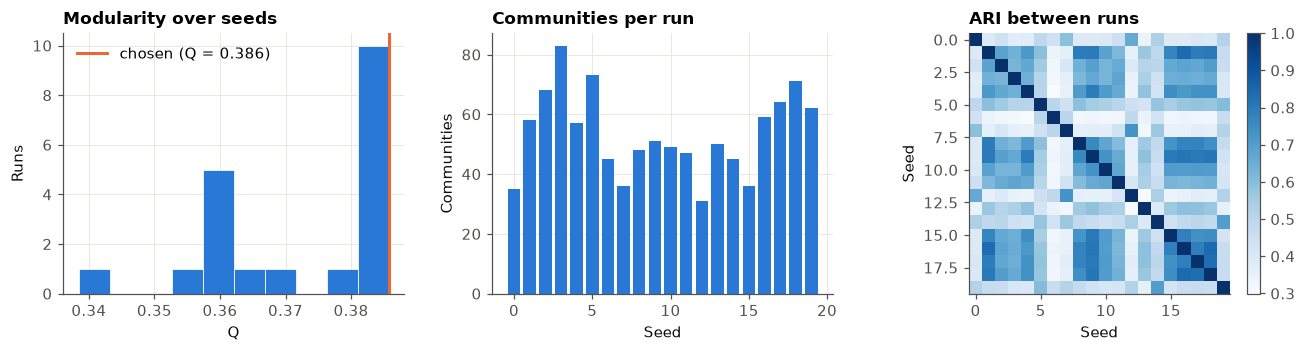

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
axes[0].hist(runs_df.Q, bins=10, color=BLUE, edgecolor="white", linewidth=0.5)
axes[0].axvline(best["Q"], color=ORANGE, lw=2, label=f"chosen (Q = {best['Q']:.3f})")
axes[0].set(title="Modularity over seeds", xlabel="Q", ylabel="Runs")
axes[0].legend(frameon=False)
axes[1].bar(runs_df.index, runs_df.n_comm, color=BLUE)
axes[1].set(title="Communities per run", xlabel="Seed", ylabel="Communities")
im = axes[2].imshow(ari, cmap="Blues", vmin=ari[iu].min(), vmax=1)
axes[2].set(title="ARI between runs", xlabel="Seed", ylabel="Seed")
axes[2].grid(False)
fig.colorbar(im, ax=axes[2], fraction=0.046)
fig.tight_layout()
fig.savefig(FIGURES / "02_louvain_seeds.png")
plt.show()

> **What we found.**
> - **Modularity:** $Q$ = 0.372 ± 0.014 over 20 seeds (range 0.338–0.386). The chosen run (seed 9) has $Q$ = **0.3857** and **51 communities**. Values between 0.3 and 0.7 are usually read as a clear community structure, so the friendship graph is clustered, but only moderately.
> - **The number of communities varies a lot** between runs (31 to 83, mean 53). Most of the extra communities are tiny (see 2f).
> - **Stability is only moderate:** two runs agree with ARI 0.54 on average (min 0.30, max 0.84) and NMI 0.52. The large-scale structure comes back every time, but the boundaries between the big communities move from run to run.
> - Louvain finds most of its modularity early: the first level already has $Q$ = 0.374 (529 communities), and the later aggregations only add 0.012.
> - **Louvain's connectivity defect is real here:** 15 of the 20 runs left at least one community internally disconnected (23 such communities in total). The fix splits them; it raises $Q$ by at most 0.00004, so it changes almost nothing in quality, but it guarantees that every community is a connected group of friends. The chosen run had no disconnected community.
>
> **Consequence for the comparison with the taste communities.** Picking the best-$Q$ run is a legitimate choice, but it is still one draw. In step 5, NMI/ARI against the taste partition should also be computed on the other runs, which are saved in `philadelphia_pa_friend_communities_all_seeds.parquet` (section 2h), so that we can say how much of the result is just Louvain's randomness.

## 2e. The resolution parameter

Modularity has a known **resolution limit**: with $\gamma=1$ it can merge small communities or, on some graphs, split large ones. The parameter $\gamma$ moves the scale: larger values give more and smaller communities. We run Louvain for several values and look at how the number of communities changes, and how good each partition is **as judged by the standard modularity** ($\gamma=1$), which is the only value that is comparable across rows.

We keep $\gamma=1$ unless the table shows a good reason to change: it is the definition used in the course, it makes our numbers comparable with the literature, and there is no ground truth that would tell us which scale is the "right" one.

In [7]:
res_rows = []
t0 = time.perf_counter()
for g in RESOLUTIONS:
    for s in range(SEEDS_PER_RESOLUTION):
        part = louvain_connected(G, gamma=g, seed=100 + s)
        sizes = np.array(sorted(Counter(part.values()).values(), reverse=True))
        res_rows.append({"gamma": g, "seed": s, "n_comm": len(sizes), "Q_standard": modularity(G, part, 1.0),
                         "Q_gamma": modularity(G, part, g), "largest": sizes[0],
                         "communities_ge10": int((sizes >= 10).sum())})
print(f"{len(res_rows)} runs in {time.perf_counter() - t0:.0f} s")
res_df = pd.DataFrame(res_rows)
res_table = res_df.groupby("gamma").agg(n_comm=("n_comm", "mean"), communities_ge10=("communities_ge10", "mean"),
                                        largest=("largest", "mean"), Q_standard=("Q_standard", "mean"),
                                        Q_standard_sd=("Q_standard", "std"))
res_table.round(4)

30 runs in 21 s


,n_comm,communities_ge10,largest,Q_standard,Q_standard_sd
gamma,,,,,
0.50,51.2,4.8,5345.4,0.1979,0.1064
0.75,60.0,10.6,3123.2,0.3567,0.0133
1.00,53.8,12.0,2444.6,0.3800,0.0041
1.25,35.0,15.6,1819.8,0.3694,0.0061
1.50,28.6,21.4,1239.0,0.3480,0.0053
2.00,39.8,38.0,946.8,0.3184,0.0047


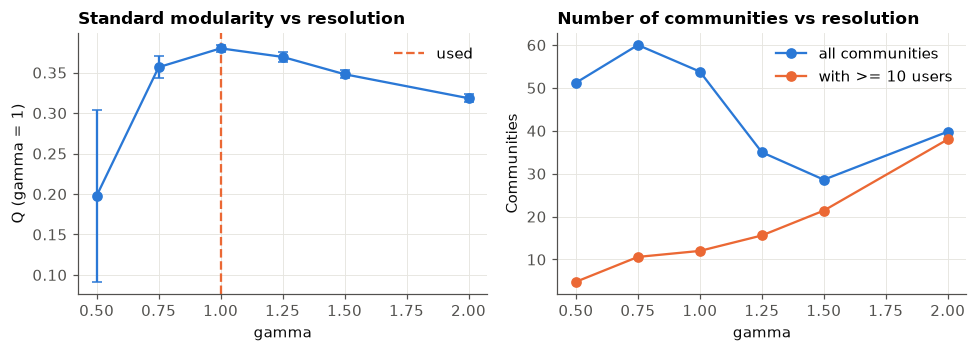

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.3))
axes[0].errorbar(res_table.index, res_table.Q_standard, yerr=res_table.Q_standard_sd, marker="o", color=BLUE, capsize=3)
axes[0].axvline(RESOLUTION, color=ORANGE, ls="--", label="used")
axes[0].set(title="Standard modularity vs resolution", xlabel="gamma", ylabel="Q (gamma = 1)")
axes[0].legend(frameon=False)
axes[1].plot(res_table.index, res_table.n_comm, marker="o", color=BLUE, label="all communities")
axes[1].plot(res_table.index, res_table.communities_ge10, marker="o", color=ORANGE, label="with >= 10 users")
axes[1].set(title="Number of communities vs resolution", xlabel="gamma", ylabel="Communities")
axes[1].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "02_resolution.png")
plt.show()

> **What we found.**
> - **$\gamma = 1$ gives the best standard modularity** (0.380 ± 0.004) and also the lowest spread between seeds of all the values tried.
> - **$\gamma = 0.5$ is clearly too small:** the largest community swallows 5,345 users (67%), $Q$ drops to 0.20 and the runs disagree wildly (sd 0.11). This is the resolution limit in action.
> - Larger $\gamma$ splits the graph into more communities of reasonable size: the number of communities with at least 10 users goes from 12 ($\gamma = 1$) to 38 ($\gamma = 2$), at the cost of $Q$ (0.318 at $\gamma = 2$).
>
> **Decision:** we keep $\gamma = 1$ (best $Q$, the course definition). If the later comparison needs more, smaller friend communities, $\gamma = 1.5$ or $2$ is the natural alternative to report.

## 2f. Analysing the final communities

From here on, **the partition is the best run of section 2d**. Communities are renumbered by size (0 = largest). For each community we compute:
- size, and **internal density** (internal edges over possible pairs);
- the **share of edge ends that stay inside** the community (a community that keeps most of its friendships inside is well separated);
- its **contribution to $Q$**;
- how many **hubs** it contains (top 1% of users by number of friends) and what share of its internal edges touch a hub: a high share means the community is held together by a few very connected people;
- profile of the members: mean number of fans, median year of joining Yelp, mean rating.

In [9]:
part = best["part"]
size_rank = {c: r for r, (c, _) in enumerate(Counter(part.values()).most_common())}
part = {u: size_rank[c] for u, c in part.items()}        # renumber: 0 = largest community
assert abs(modularity(G, part) - best["Q"]) < 1e-9

U = users.copy()
U["community"] = pd.Series(part)
hub_cut = U.degree.quantile(HUB_QUANTILE)
U["is_hub"] = U.degree >= hub_cut
print(f"Hubs: users with >= {hub_cut:.0f} friends -> {U.is_hub.sum()} users ({U.is_hub.mean():.1%})")

E = edges.copy()
E["cu"], E["cv"] = E.u.map(part), E.v.map(part)
E["hub_edge"] = E.u.map(U.is_hub) | E.v.map(U.is_hub)
m = len(E)

rows = []
for c, grp in U.groupby("community"):
    n = len(grp)
    e_int = int(((E.cu == c) & (E.cv == c)).sum())
    e_cut = int(((E.cu == c) != (E.cv == c)).sum())     # edges with exactly one end inside
    tot = int(grp.degree.sum())
    rows.append({"community": c, "users": n, "internal_edges": e_int, "boundary_edges": e_cut,
                 "density": e_int / (n * (n - 1) / 2) if n > 1 else np.nan,
                 "ends_inside": 2 * e_int / tot if tot else np.nan,
                 "Q_contribution": 2 * e_int / (2 * m) - (tot / (2 * m)) ** 2,
                 "hubs": int(grp.is_hub.sum()),
                 "hub_edge_share": float(E.loc[(E.cu == c) & (E.cv == c), "hub_edge"].mean()) if e_int else np.nan,
                 "mean_fans": grp.fans.mean(), "median_join_year": grp.yelping_since.dt.year.median(),
                 "mean_stars": grp.mean_stars.mean()})
comm_df = pd.DataFrame(rows).set_index("community")
assert abs(comm_df.Q_contribution.sum() - best["Q"]) < 1e-9, "contributions must add up to Q"

sizes = comm_df.users
print(f"Communities: {len(comm_df)}   sizes: largest {sizes.max():,}, median {sizes.median():.0f}, smallest {sizes.min()}")
print(f"Communities with >= 50 users: {(sizes >= 50).sum()} (they hold {sizes[sizes >= 50].sum() / sizes.sum():.1%} of the users)")
print(f"Communities with < 10 users : {(sizes < 10).sum()} (they hold {sizes[sizes < 10].sum()} users)")
print(f"Edges inside communities: {(E.cu == E.cv).mean():.1%}")
comm_df.head(15).style.format({"users": "{:,}", "internal_edges": "{:,}", "boundary_edges": "{:,}", "density": "{:.3f}",
                               "ends_inside": "{:.1%}", "Q_contribution": "{:.4f}", "hub_edge_share": "{:.1%}",
                               "mean_fans": "{:.1f}", "median_join_year": "{:.0f}", "mean_stars": "{:.2f}"})

Hubs: users with >= 179 friends -> 81 users (1.0%)
Communities: 51   sizes: largest 2,460, median 3, smallest 2
Communities with >= 50 users: 9 (they hold 97.2% of the users)
Communities with < 10 users : 38 (they hold 132 users)
Edges inside communities: 63.6%


,users,internal_edges,boundary_edges,density,ends_inside,Q_contribution,hubs,hub_edge_share,mean_fans,median_join_year,mean_stars
community,,,,,,,,,,,
0,"2,460","15,563","14,040",0.005,68.9%,0.1186,24,52.1%,11.6,2014,4.00
1,"1,667","7,707","8,130",0.006,65.5%,0.0837,14,38.3%,9.8,2009,3.76
2,"1,607","12,916","16,245",0.010,61.4%,0.0942,38,46.8%,13.1,2011,3.80
3,818,"2,875","3,663",0.009,61.1%,0.0377,0,0.0%,6.0,2013,3.95
4,661,"3,136","5,090",0.014,55.2%,0.0393,5,15.0%,113.4,2010,3.89
5,196,241,650,0.013,42.6%,0.0035,0,0.0%,2.1,2012,3.84
6,123,134,319,0.018,45.7%,0.0020,0,0.0%,2.0,2012,3.88
7,98,107,329,0.023,39.4%,0.0016,0,0.0%,2.9,2012,3.96
8,96,161,318,0.035,50.3%,0.0024,0,0.0%,2.5,2012,3.96


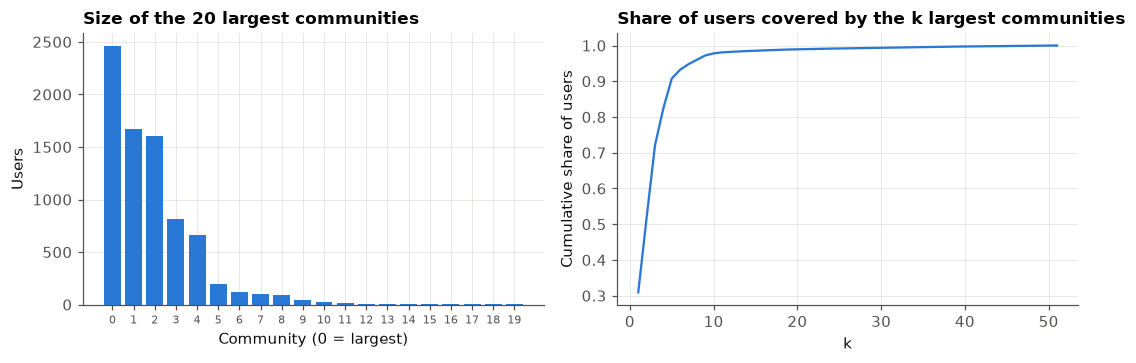

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
top = comm_df.head(20)
axes[0].bar(top.index.astype(str), top.users, color=BLUE)
axes[0].set(title="Size of the 20 largest communities", xlabel="Community (0 = largest)", ylabel="Users")
axes[0].tick_params(axis="x", labelsize=7)
cum = sizes.sort_values(ascending=False).cumsum() / sizes.sum()
axes[1].plot(np.arange(1, len(cum) + 1), cum.values, color=BLUE)
axes[1].set(title="Share of users covered by the k largest communities", xlabel="k", ylabel="Cumulative share of users")
fig.tight_layout()
fig.savefig(FIGURES / "02_community_sizes.png")
plt.show()

> **What we found.**
> - **The partition is very unbalanced.** Of 51 communities, only 9 have at least 50 users, and they hold 97.2% of the users; the five largest alone hold 91% (2,460 / 1,667 / 1,607 / 818 / 661). The other 38 communities have fewer than 10 users each (132 users in total).
> - **The three largest communities carry most of the modularity**: 0.119 + 0.084 + 0.094 = 0.297 of the total 0.386.
> - **63.6% of all friendships are inside a community**, so a user's friends are mostly, but not overwhelmingly, in the same community. For the five largest communities the share of edge ends that stay inside is 55–69%.
> - **Hubs sit in the big communities.** All 81 hubs (≥ 179 friends) are in the 9 largest communities (24 in community 0, 38 in community 2, 14 in community 1, 5 in community 4, none in community 3). They are 1% of the users but **45% of all friendships touch a hub**; in communities 0 and 2 about half of the internal edges do. Community 3 has no hub at all, so it is not held together by one.
> - **The communities differ in who is in them.** Community 4 has a mean of 113 fans per user, against 2–13 elsewhere: it looks like a group of very popular reviewers. Communities 0 and 1 differ by cohort (median join year 2014 against 2009); the next subsection shows how strong this effect is. Communities 5–9 have almost no fans (about 2 per user) and no hubs.
> - Internal density looks low (0.005 for the largest community) simply because the communities are large and the graph is sparse (overall density 0.002), so it should not be read as "weakly connected".

### Do the communities reflect *when* users were active?

The members' join years above already differ between communities. This matters for the whole project: two users who were active in the same years review restaurants that **existed in those years** (40% of the restaurants are now closed, see step 1). Their restaurant sets can then overlap without any shared taste. If the friend communities are largely "periods of activity", part of any friend–taste overlap found in step 5 could be explained by time alone.

For every user we take the **median year of their restaurant reviews**, and for each community with at least 50 users we compare the distribution of that year and the share of its reviews that are about restaurants closed today. We then measure how much the community label tells us about the period of activity (NMI between community and period, the period split into four bins), against the same NMI with shuffled community labels.

In [11]:
reviews = pd.read_parquet(P + "reviews.parquet")
biz = pd.read_parquet(P + "businesses.parquet").set_index("business_id")
reviews["community"] = reviews.user_id.map(part)
reviews["closed_now"] = reviews.business_id.map(biz.is_open) == 0
U["median_review_year"] = reviews.groupby("user_id").date.median().dt.year

big_c = comm_df.index[comm_df.users >= 50]
B = U[U.community.isin(big_c)]
era = (B.groupby("community").median_review_year
         .describe()[["count", "25%", "50%", "75%"]]
         .rename(columns={"count": "users", "25%": "year_q25", "50%": "year_median", "75%": "year_q75"})
         .join(reviews[reviews.community.isin(big_c)].groupby("community").closed_now.mean().rename("reviews_of_closed")))

PERIOD_BINS = [0, 2010, 2013, 2016, 2100]           # <=2010, 2011-13, 2014-16, >=2017
period = pd.cut(B.median_review_year, PERIOD_BINS).astype(str)
nmi_era = normalized_mutual_info_score(B.community, period)
rng = np.random.default_rng(SEED)
nmi_shuffled = [normalized_mutual_info_score(rng.permutation(B.community.values), period) for _ in range(100)]
print(f"NMI(friend community, period of activity) = {nmi_era:.3f}   "
      f"shuffled labels: mean {np.mean(nmi_shuffled):.4f}, max {np.max(nmi_shuffled):.4f} (100 shuffles)")
era.style.format({"users": "{:,.0f}", "year_q25": "{:.0f}", "year_median": "{:.0f}", "year_q75": "{:.0f}",
                  "reviews_of_closed": "{:.1%}"})

NMI(friend community, period of activity) = 0.223   shuffled labels: mean 0.0010, max 0.0018 (100 shuffles)


,users,year_q25,year_median,year_q75,reviews_of_closed
community,,,,,
0,"2,460",2016,2018,2019,19.7%
1,"1,667",2009,2010,2012,39.3%
2,"1,607",2012,2013,2015,33.8%
3,818,2014,2016,2018,24.5%
4,661,2012,2015,2017,23.8%
5,196,2013,2014,2016,32.1%
6,123,2014,2015,2016,31.9%
7,98,2013,2015,2017,30.0%
8,96,2013,2015,2017,26.5%


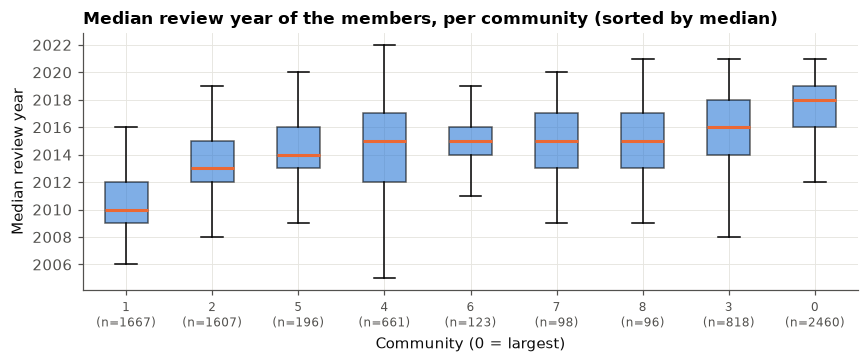

In [12]:
order_c = era.sort_values("year_median").index
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.boxplot([B.loc[B.community == c, "median_review_year"] for c in order_c], showfliers=False,
           patch_artist=True, boxprops=dict(facecolor=BLUE, alpha=0.6), medianprops=dict(color=ORANGE, lw=2))
ax.set_xticks(range(1, len(order_c) + 1), [f"{c}\n(n={int(era.users[c])})" for c in order_c], fontsize=8)
ax.set(title="Median review year of the members, per community (sorted by median)",
       xlabel="Community (0 = largest)", ylabel="Median review year")
ax.yaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
fig.tight_layout()
fig.savefig(FIGURES / "02_activity_period.png")
plt.show()

> **What we found.** **The friend communities are to a large extent periods of activity.**
> - The medians range from **2010** for community 1 (half of its members between 2009 and 2012) to **2018** for community 0 (2016–2019). Community 2 sits at 2013, communities 3–8 at 2014–2016.
> - The older the community, the more of its reviews are about restaurants that have since closed: **39%** for community 1 against **20%** for community 0 (29% over all reviews).
> - The community label says a lot about the period: NMI = **0.223**, against 0.001 (max 0.002) with shuffled labels.
>
> This is plausible (people who joined Yelp in the same years met at the same events and befriended each other) and it is not a flaw of the communities. **It is a confounder for step 5**: two friends active in the same years can only review the restaurants that were open then, so their restaurant sets overlap partly because of *time*, not *taste*. Step 5 should therefore check that a friend–taste overlap survives a control for the period, for example a permutation test that shuffles labels only **within** the same period, or a comparison of NMI(taste, friends) with NMI(taste, period).

## 2g. Robustness checks

Two questions decide whether the communities mean anything:

1. **Are they created by the hubs?** A handful of users with hundreds or thousands of friends can glue a graph together. We remove the hubs, run Louvain again on what is left (its largest connected component), and compare with the full partition on the users that remain.
2. **Is the modularity higher than chance?** Any sparse graph has some modularity. The fair reference is a random graph with **exactly the same degree of every user** (degree-preserving edge swaps), which keeps the hubs but destroys who is friends with whom. If our $Q$ is far above the random one, the community structure is real.

In [13]:
# 1. remove the hubs
G_nh = G.subgraph([u for u in G if not U.is_hub[u]]).copy()
lcc = max(nx.connected_components(G_nh), key=len)
G_nh = G_nh.subgraph(lcc).copy()
print(f"Without hubs: {G_nh.number_of_nodes():,} users in the largest component "
      f"({G_nh.number_of_nodes() / (G.number_of_nodes() - U.is_hub.sum()):.1%} of the non-hubs), {G_nh.number_of_edges():,} edges")

nh_runs = [louvain_connected(G_nh, seed=s) for s in range(5)]
nh_best = max(nh_runs, key=lambda p: modularity(G_nh, p))
common = list(G_nh.nodes())
a = [part[u] for u in common]
nh_ari = [adjusted_rand_score(a, [p[u] for u in common]) for p in nh_runs]
nh_nmi = [normalized_mutual_info_score(a, [p[u] for u in common]) for p in nh_runs]
print(f"Q without hubs: {np.mean([modularity(G_nh, p) for p in nh_runs]):.4f}   communities: {n_communities(nh_best)}")
print(f"Agreement with the full partition on the remaining users: ARI {np.mean(nh_ari):.3f}, NMI {np.mean(nh_nmi):.3f}")
print(f"(for reference, agreement between two runs on the full graph: ARI {ari[iu].mean():.3f}, NMI {nmi[iu].mean():.3f})")

Without hubs: 7,113 users in the largest component (90.4% of the non-hubs), 36,822 edges


Q without hubs: 0.4881   communities: 35
Agreement with the full partition on the remaining users: ARI 0.485, NMI 0.480
(for reference, agreement between two runs on the full graph: ARI 0.538, NMI 0.522)


In [14]:
# 2. degree-preserving random graphs
null_Q, null_n = [], []
t0 = time.perf_counter()
for s in range(N_NULL_GRAPHS):
    Gn = G.copy()
    nx.double_edge_swap(Gn, nswap=5 * G.number_of_edges(), max_tries=500 * G.number_of_edges(), seed=s)
    pn = louvain_connected(Gn, seed=s)
    null_Q.append(modularity(Gn, pn)); null_n.append(n_communities(pn))
    assert dict(Gn.degree()) == dict(G.degree())
print(f"{N_NULL_GRAPHS} random graphs in {time.perf_counter() - t0:.0f} s")
# Fair comparison: one Louvain run per random graph vs the AVERAGE run on the real graph (not the best of 20).
print(f"Random graphs with the same degrees: Q = {np.mean(null_Q):.4f} (values {np.round(null_Q, 4).tolist()}), "
      f"communities {null_n}")
print(f"Real friendship graph, mean run    : Q = {runs_df.Q.mean():.4f}  (best of {N_SEEDS} runs: {best['Q']:.4f})")

3 random graphs in 12607 s
Random graphs with the same degrees: Q = 0.1706 (values [0.1717, 0.1705, 0.1695]), communities [23, 25, 25]
Real friendship graph, mean run    : Q = 0.3724  (best of 20 runs: 0.3857)


> **What we found.**
> - **Hubs blur the boundaries but do not create the communities.** Removing the 81 hubs leaves 7,113 users in one connected component (90.4% of the others). Louvain on that graph reaches $Q$ = 0.488 (35 communities), higher than with the hubs, which suggests that the hubs connect different communities. The new partition agrees with the full one on the remaining users with ARI 0.49 and NMI 0.48, about as much as two runs on the full graph agree with each other (0.54 / 0.52). The structure is therefore mostly the same, up to Louvain's own noise. ($Q$ values of two different graphs are not directly comparable, so this is only an indication.)
> - **The modularity is far above chance.** Random graphs with the same degree for every user still reach $Q$ = 0.171 (the heavy-tailed degrees alone create some apparent structure). The fair comparison is with an average run on the real graph, since each random graph also got a single run: **0.372, more than twice as much** (the best of 20 runs, 0.386, would flatter the real graph). The friendship communities are real and not an artifact of the degree distribution.

## 2h. Saving the partition

The output for the next steps is one row per user:

| File | One row per | Columns |
|---|---|---|
| `philadelphia_pa_friend_communities.parquet` | user in the LCC (7,947) | `user_id`, `friend_community` (integer, 0 = largest community) |
| `philadelphia_pa_friend_communities_all_seeds.parquet` | user in the LCC | `user_id`, `seed_0` … `seed_19`: the partition of every run of section 2d (after the connectivity fix) |
| `friend_communities_summary.json` | | parameters and the main numbers, to quote in the report |

Step 5 (NMI / ARI between friend and taste communities, permutation test) uses the first file for the main result and the second one to check that the result does not depend on Louvain's random seed. The community ids are **arbitrary labels**, and only the grouping matters.

In [15]:
out = (pd.Series(part, name="friend_community").rename_axis("user_id").reset_index()
         .sort_values("user_id").reset_index(drop=True))
assert len(out) == users.shape[0] and out.user_id.is_unique and set(out.user_id) == set(users.index)
out.to_parquet(P + "friend_communities.parquet", index=False)

all_seeds = (pd.DataFrame({f"seed_{r['seed']}": pd.Series(r["part"]) for r in runs})
               .rename_axis("user_id").reset_index().sort_values("user_id").reset_index(drop=True))
assert len(all_seeds) == len(out) and (all_seeds.user_id.values == out.user_id.values).all()
assert adjusted_rand_score(all_seeds[f"seed_{best['seed']}"], out.friend_community) == 1.0, "chosen run must match"
all_seeds.to_parquet(P + "friend_communities_all_seeds.parquet", index=False)

summary = {
    "algorithm": "Louvain, implemented from scratch (this notebook)", "resolution": RESOLUTION,
    "n_seeds": N_SEEDS, "chosen_seed": int(best["seed"]),
    "graph": {"users": G.number_of_nodes(), "edges": G.number_of_edges()},
    "modularity": {"chosen": best["Q"], "mean_over_seeds": float(runs_df.Q.mean()), "sd_over_seeds": float(runs_df.Q.std()),
                   "min": float(runs_df.Q.min()), "max": float(runs_df.Q.max())},
    "communities": {"chosen": int(best["n_comm"]), "mean_over_seeds": float(runs_df.n_comm.mean()),
                    "largest": int(sizes.max()), "with_at_least_50_users": int((sizes >= 50).sum())},
    "stability_between_seeds": {"ARI_mean": float(ari[iu].mean()), "ARI_min": float(ari[iu].min()),
                                "NMI_mean": float(nmi[iu].mean()), "NMI_min": float(nmi[iu].min())},
    "without_hubs": {"hub_definition": f"top {1 - HUB_QUANTILE:.0%} by degree (>= {hub_cut:.0f} friends)",
                     "ARI_with_full_partition": float(np.mean(nh_ari)), "NMI_with_full_partition": float(np.mean(nh_nmi))},
    "random_degree_preserving_graphs": {"modularity_mean": float(np.mean(null_Q)), "modularity_values": null_Q,
                                        "compare_with": "modularity.mean_over_seeds (one run per graph on both sides)"},
    "connectivity_fix": {"runs_with_disconnected_communities": int((runs_df.split_communities > 0).sum()),
                         "disconnected_communities_total": int(runs_df.split_communities.sum()),
                         "max_Q_gain": float(gain.max())},
    "activity_period": {"NMI_community_vs_period": float(nmi_era), "NMI_shuffled_mean": float(np.mean(nmi_shuffled)),
                        "period_bins": "<=2010, 2011-2013, 2014-2016, >=2017 (median review year of the user)",
                        "communities_used": "communities with >= 50 users"},
    "share_of_edges_inside_communities": float((E.cu == E.cv).mean()),
    "files": ["philadelphia_pa_friend_communities.parquet", "philadelphia_pa_friend_communities_all_seeds.parquet"],
}
(DATA_PROCESSED / "friend_communities_summary.json").write_text(json.dumps(summary, indent=2))
print(f"{(P + 'friend_communities.parquet')} written: {len(out):,} rows")
print(f"{(P + 'friend_communities_all_seeds.parquet')} written: {all_seeds.shape[0]:,} rows x {all_seeds.shape[1] - 1} partitions")
print("friend_communities_summary.json written")
out.friend_community.value_counts().head(10)

C:\Users\matti\m\DTU\Corsi\Computational Tools for Data Science\progetto\repo\Computational-tools-4-datasciense\data\processed\philadelphia_pa_friend_communities.parquet written: 7,947 rows
C:\Users\matti\m\DTU\Corsi\Computational Tools for Data Science\progetto\repo\Computational-tools-4-datasciense\data\processed\philadelphia_pa_friend_communities_all_seeds.parquet written: 7,947 rows x 20 partitions
friend_communities_summary.json written


friend_community
0    2460
1    1667
2    1607
3     818
4     661
5     196
6     123
7      98
8      96
9      45
Name: count, dtype: int64

### How later steps load the friend communities
```python
import pandas as pd
fc = pd.read_parquet("data/processed/philadelphia_pa_friend_communities.parquet")   # user_id, friend_community
friend_labels = fc.set_index("user_id")["friend_community"]
# e.g. NMI / ARI against a taste partition `taste_labels` (a Series indexed by user_id):
# from sklearn.metrics import normalized_mutual_info_score as nmi
# nmi(friend_labels.loc[common], taste_labels.loc[common])

# robustness: the same comparison on all 20 Louvain runs
all_seeds = pd.read_parquet("data/processed/philadelphia_pa_friend_communities_all_seeds.parquet").set_index("user_id")
# scores = [nmi(all_seeds.loc[common, col], taste_labels.loc[common]) for col in all_seeds.columns]
```

## Summary of step 2

**Result:** Louvain (our own implementation, validated against `networkx` and on the karate club) finds **51 friend communities** in the Philadelphia graph. A typical run reaches modularity **0.372 ± 0.014** (20 seeds; the chosen run 0.386), against 0.171 for random graphs with the same degrees. The communities are real, but they are unbalanced, only moderately stable between runs, and strongly tied to the period in which their members were active.

### Decision log

| # | Decision | Reason / evidence |
|---|---|---|
| 1 | Louvain **implemented from scratch** (local moving + aggregation) | Required for a technically challenging project; matches `networkx` on Q (0.3756 vs 0.3758) and reaches the best known 0.4198 on the karate club. |
| 2 | Resolution $\gamma = 1$ | Best standard modularity in the sweep (0.380); $\gamma = 0.5$ collapses into one giant community. |
| 3 | Final partition = best-$Q$ run of 20 seeds (seed 9) | Louvain is randomised; between-run agreement is only ARI 0.54, so the choice is reported, not hidden. |
| 4 | Keep the hubs | Removing them keeps the structure (ARI 0.49). Dropping them would remove 1% of the users and the 45% of all friendships that touch a hub. |
| 5 | Keep the 38 tiny communities (132 users) | Dropping them would lose users; they should be treated carefully (or merged) in step 5. |
| 6 | Split internally disconnected communities into their components | 15 of 20 Louvain runs produced at least one; splitting never lowers $Q$ (gain ≤ 0.00004) and makes every community a connected group of friends. |

### Notes for the next steps
- **Step 5 (comparison):** use `philadelphia_pa_friend_communities.parquet` for the main result. Because the partition is unbalanced (5 communities hold 91% of the users) and Louvain is not very stable (ARI 0.54), repeat NMI/ARI on the 20 runs in `philadelphia_pa_friend_communities_all_seeds.parquet` (and possibly with $\gamma = 1.5$).
- **Step 5, confounder:** friend communities are strongly tied to the period of activity (NMI 0.22 against 0.001 by chance, section 2f). The permutation test should shuffle labels within the same period, or the result should be compared with NMI(taste, period); otherwise a shared period could be mistaken for shared taste.
- **Limitations to report:** modularity of 0.37 is moderate; 36% of the friendships cross communities; selection bias of step 1 (only active, connected reviewers); Louvain leaves disconnected communities, which we fix afterwards (Leiden, not used here, avoids them by construction); friendships have no date, so we cannot tell whether friends met before or after reviewing.